# 04 — CNN simple entrenada desde cero

**Fase CRISP-DM:** modelado.

La red se define en `src/models/cnn.py` y se entrena con `python -m src.training.entrenar cnn --variante base|doble` (en CPU, unos 20 minutos la base y 2 horas la doble). Este notebook carga los modelos y los historiales guardados, revisa la aumentación, las curvas de entrenamiento y los errores. La formulación está en `docs/formulacion_matematica.md`, sección 5.4.

Se entrenaron dos variantes, que solo difieren en el número de convoluciones por bloque:
- **base**: una convolución por bloque (primera versión);
- **doble**: dos convoluciones por bloque. Se probó porque la versión base mostró subajuste (sección 4).

In [1]:
import sys, json, os
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ["PYTHONPATH"] = str(RAIZ)  # para los procesos de joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from src.config import RESULTADOS, CLASES_ENTRENAMIENTO, SEMILLA
from src.data.recortes import cargar_conjunto
from src.evaluation.evaluar import graficar_matriz_confusion
from src.models.cnn import VARIANTES, VARIANTE_FINAL, capas_aumentacion, cargar_imagenes, rutas_cnn
from src.utils.visualizacion import estilo, guardar_figura

estilo()
CLASES = CLASES_ENTRENAMIENTO
res = {v: json.loads(rutas_cnn(v)["resultados"].read_text(encoding="utf8")) for v in VARIANTES}
hist = {v: pd.read_csv(rutas_cnn(v)["historial"]) for v in VARIANTES}
modelo = keras.models.load_model(rutas_cnn(VARIANTE_FINAL)["modelo"])
print(f"TensorFlow {tf.__version__}; variante final: {VARIANTE_FINAL}")
pd.DataFrame({v: {"parámetros": r["parametros"], "épocas": r["epocas"], "mejor época": r["mejor_epoca"],
                  "minutos": round(r["tiempo_entrenamiento_s"] / 60, 1)} for v, r in res.items()}).T

TensorFlow 2.20.0; variante final: doble


,parámetros,épocas,mejor época,minutos
base,102306.0,35.0,25.0,22.0
doble,296738.0,66.0,54.0,255.5


## 1. Arquitectura de la variante final

In [2]:
modelo.summary(line_length=100)

Model: "cnn_calidad"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)                   │ (None, 128, 128, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ aumentacion (Sequential)                   │ (None, 128, 128, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ rescaling (Rescaling)                      │ (None, 128, 128, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d (Conv2D)                            │ (None, 128, 128, 32)            │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization (BatchNormalization)   │ (None, 128, 128, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ re_lu (ReLU)                               │ (None, 128, 128, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_1 (Conv2D)                          │ (None, 128, 128, 32)            │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_1 (BatchNormalization) │ (None, 128, 128, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ re_lu_1 (ReLU)                             │ (None, 128, 128, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d (MaxPooling2D)               │ (None, 64, 64, 32)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_2 (Conv2D)                          │ (None, 64, 64, 64)              │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_2 (BatchNormalization) │ (None, 64, 64, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ re_lu_2 (ReLU)                             │ (None, 64, 64, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_3 (Conv2D)                          │ (None, 64, 64, 64)              │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_3 (BatchNormalization) │ (None, 64, 64, 64)              │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ re_lu_3 (ReLU)                             │ (None, 64, 64, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d_1 (MaxPooling2D)             │ (None, 32, 32, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_4 (Conv2D)                          │ (None, 32, 32, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_4 (BatchNormalization) │ (None, 32, 32,

 Total params: 888,424 (3.39 MB)

 Trainable params: 295,842 (1.13 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 591,686 (2.26 MB)

## 2. Aumentación de datos

En cada época cada imagen de entrenamiento pasa por volteos horizontales y verticales, una rotación aleatoria entre −180° y 180° y un zoom de ±10 %. Ninguna de esas transformaciones cambia la calidad de la fruta, así que la red ve más variedad sin datos nuevos. El relleno es negro, igual que el fondo del recorte. En validación y prueba la aumentación está apagada.

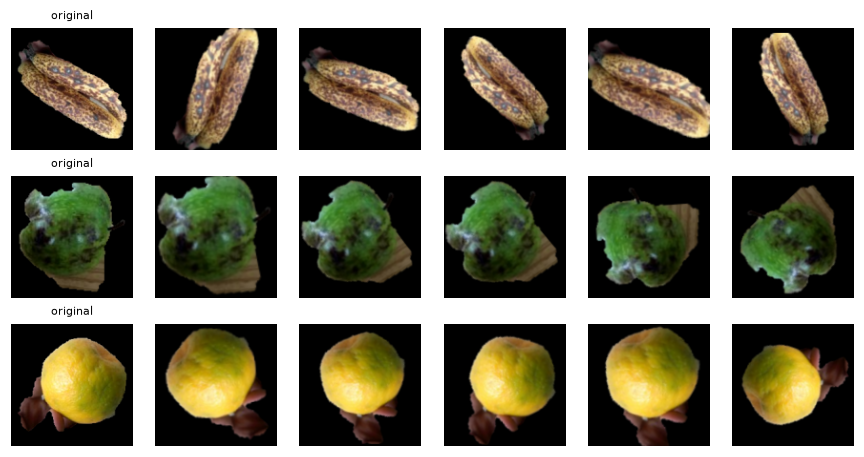

In [3]:
conj = cargar_conjunto()
ej = conj[conj["particion"] == "train"].groupby("fruta").sample(1, random_state=SEMILLA)
imgs = cargar_imagenes(ej["recorte"])
aug = capas_aumentacion()
fig, axes = plt.subplots(3, 6, figsize=(8, 4.2))
for i in range(3):
    axes[i, 0].imshow(imgs[i]); axes[i, 0].set_title("original", fontsize=7)
    for j in range(1, 6):
        axes[i, j].imshow(aug(imgs[i:i + 1].astype("float32"), training=True)[0].numpy().astype("uint8"))
    for ax in axes[i]:
        ax.axis("off")
fig.tight_layout()
guardar_figura(fig, "cnn_aumentacion", raster=True)
plt.show()

## 3. Curvas de entrenamiento

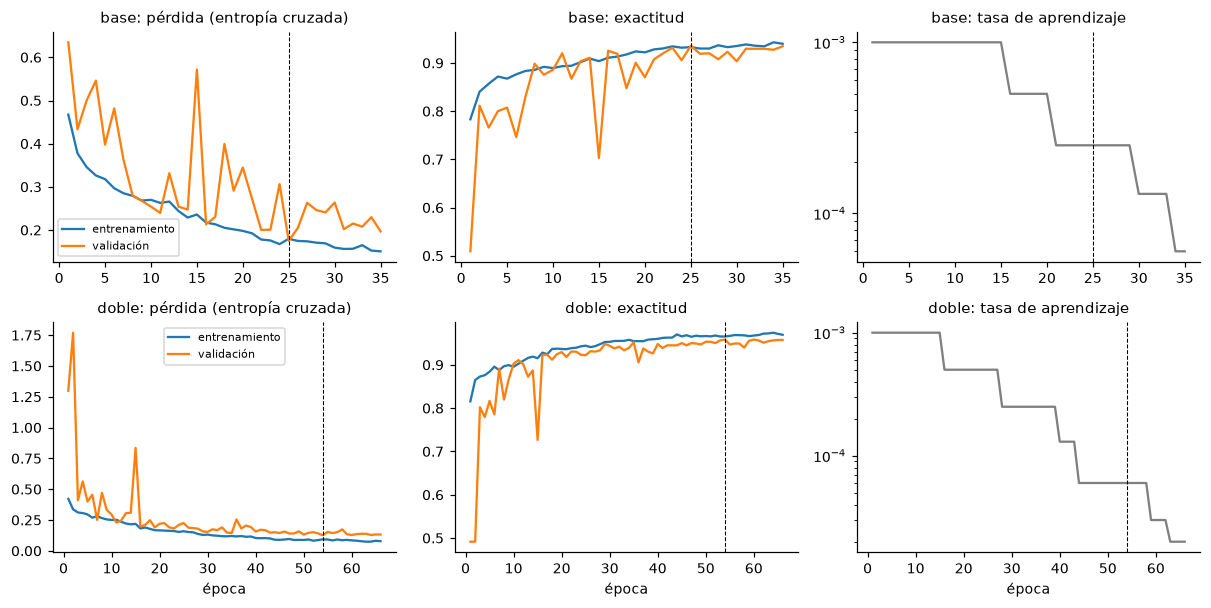

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for fila, v in zip(axes, VARIANTES):
    h, mejor = hist[v], res[v]["mejor_epoca"]
    ep = np.arange(1, len(h) + 1)
    fila[0].plot(ep, h["loss"], label="entrenamiento"); fila[0].plot(ep, h["val_loss"], label="validación")
    fila[0].set_title(f"{v}: pérdida (entropía cruzada)", fontsize=10)
    fila[1].plot(ep, h["accuracy"], label="entrenamiento"); fila[1].plot(ep, h["val_accuracy"], label="validación")
    fila[1].set_title(f"{v}: exactitud", fontsize=10)
    fila[2].semilogy(ep, h["learning_rate"], c="gray"); fila[2].set_title(f"{v}: tasa de aprendizaje", fontsize=10)
    for ax in fila:
        ax.axvline(mejor, ls="--", c="k", lw=0.7)
    fila[0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("época")
fig.tight_layout()
guardar_figura(fig, "cnn_curvas")
plt.show()

## 4. Desempeño en entrenamiento, validación y prueba

Cada partición se evalúa con los pesos de la mejor época y sin aumentación. Si entrenamiento y validación son altos y parecidos, el modelo generaliza; si son parecidos pero bajos, subajusta (le falta capacidad); si entrenamiento es mucho mayor que validación, sobreajusta.

In [5]:
tabla = pd.concat({v: pd.DataFrame({p: r[p] for p in ("train", "val", "test")}).T for v, r in res.items()})
tabla[["n", "exactitud", "f1_macro", "recall_buena", "recall_mala", "auc"]]

n  exactitud  f1_macro  recall_buena  recall_mala     auc
base  train  4563.0     0.9393    0.9393        0.9318       0.9466  0.9834
      val     966.0     0.9358    0.9358        0.9242       0.9470  0.9807
      test    966.0     0.9244    0.9243        0.9070       0.9412  0.9737
doble train  4563.0     0.9671    0.9671        0.9625       0.9716  0.9941
      val     966.0     0.9586    0.9586        0.9537       0.9633  0.9905
      test    966.0     0.9513    0.9513        0.9471       0.9554  0.9840

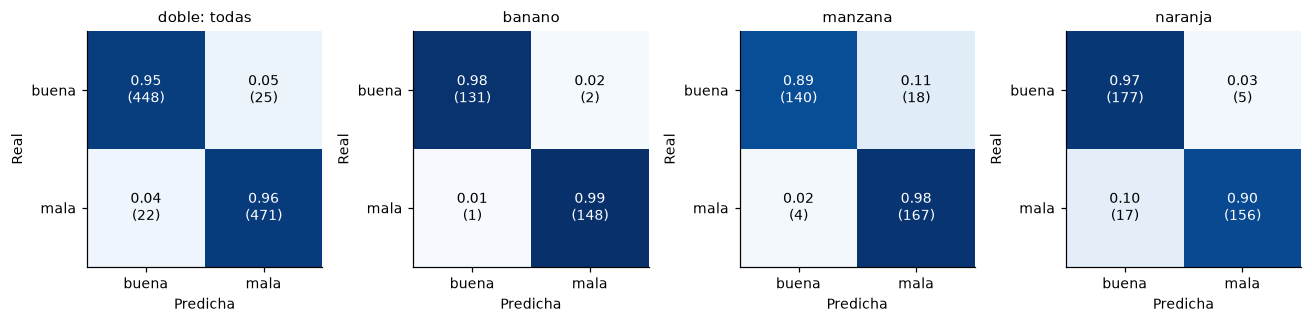

In [6]:
pred = pd.read_csv(rutas_cnn(VARIANTE_FINAL)["predicciones"])
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
graficar_matriz_confusion(axes[0], pred["real"], pred["cnn"], CLASES, f"{VARIANTE_FINAL}: todas")
for ax, (f, g) in zip(axes[1:], pred.groupby("fruta")):
    graficar_matriz_confusion(ax, g["real"], g["cnn"], CLASES, f)
fig.tight_layout()
guardar_figura(fig, "cnn_matrices_confusion")
plt.show()

## 5. Errores

Las imágenes de prueba que la variante final clasificó mal con mayor confianza. Sirven para ver si los errores son de etiqueta, de segmentación o del modelo.

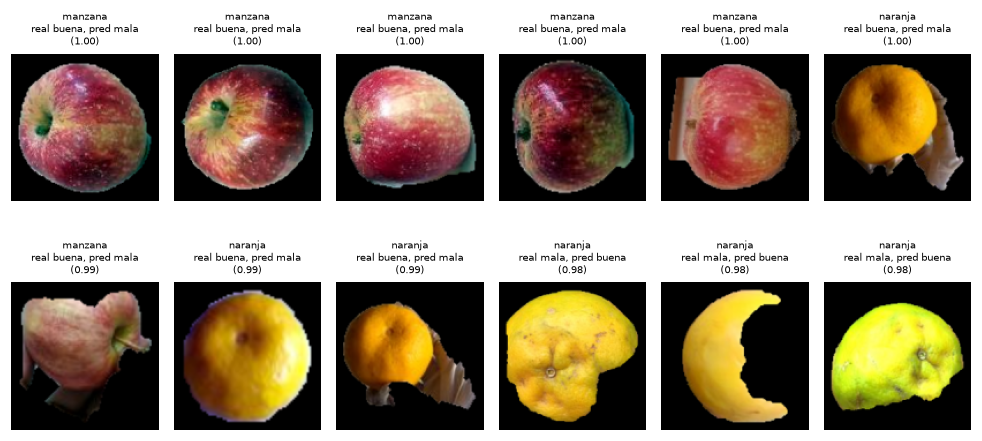

Errores en prueba: 47 de 966


In [7]:
pred["conf_error"] = np.where(pred["cnn"] == "mala", pred["cnn_prob_mala"], 1 - pred["cnn_prob_mala"])
err = pred[pred["real"] != pred["cnn"]].sort_values("conf_error", ascending=False).head(12)
err = err.merge(conj[["ruta", "recorte"]], on="ruta")
imgs = cargar_imagenes(err["recorte"])
fig, axes = plt.subplots(2, 6, figsize=(9, 4.6))
for ax, img, (_, r) in zip(axes.ravel(), imgs, err.iterrows()):
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{r['fruta']}\nreal {r['real']}, pred {r['cnn']}\n({r['conf_error']:.2f})", fontsize=6.5)
fig.tight_layout()
guardar_figura(fig, "cnn_errores", raster=True)
plt.show()
print(f"Errores en prueba: {(pred['real'] != pred['cnn']).sum()} de {len(pred)}")

## 6. Conclusiones

1. La variante **base** (1 convolución por bloque, 102 mil parámetros) **subajustó**: F1 de 0,939 en entrenamiento y 0,936 en validación, casi iguales y bajos. Le faltaba capacidad, no regularización.
2. La variante **doble** (2 convoluciones por bloque, 297 mil parámetros) corrigió el subajuste: F1 de 0,967 en entrenamiento, 0,959 en validación y **0,951 [0,937; 0,965] en prueba**, con recall de `mala` de 0,955. La brecha entre entrenamiento y prueba es de solo 0,016, así que la aumentación, el *dropout* y el *early stopping* controlan bien el sobreajuste.
3. Las curvas de validación oscilan mucho en las primeras 15 épocas (normalización por lotes con tasa de aprendizaje alta); se estabilizan cuando `ReduceLROnPlateau` baja la tasa.
4. Los errores con más confianza muestran dos problemas del dataset más que del modelo:
   - **Manzanas rojas sanas predichas como malas.** En el dataset el 57 % de las manzanas *bad* son rojas, contra el 28 % de las *good* ($a^* > 150$): la variedad está correlacionada con la etiqueta y la red aprendió "rojo intenso → mala".
   - **Recortes con mano, papel o fruta partida** (errores de segmentación), que cambian el color y la forma de la región.
5. Aun con la mejora, la CNN queda por debajo de la SVM con características manuales (0,951 contra 0,986). Con unas 4.500 imágenes y entrenada desde cero en CPU, no alcanza a superar a características de color diseñadas a mano para este problema.